<a href="https://colab.research.google.com/github/surajjeoor/masai_assignments/blob/main/Boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# Install if needed (Colab)
import subprocess, sys
for pkg in ['xgboost', 'lightgbm', 'catboost']:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import xgboost as xgb
import lightgbm as lgb
import catboost as cb

from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               VotingClassifier, StackingClassifier)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('All imports successful.')
print(f'  XGBoost  : {xgb.__version__}')
print(f'  LightGBM : {lgb.__version__}')
print(f'  CatBoost : {cb.__version__}')


All imports successful.
  XGBoost  : 3.3.0
  LightGBM : 4.6.0
  CatBoost : 1.2.10


In [38]:
# Fraud dataset -- PROVIDED
np.random.seed(99)
M = 3000
transaction_amount = np.random.exponential(200, M).clip(1, 5000).round(2)
hour_of_day        = np.random.randint(0, 24, M)
distance_from_home = np.random.exponential(30, M).clip(0, 500).round(1)
num_prev_txn_24h   = np.random.poisson(3, M)
is_foreign         = (np.random.rand(M) < 0.15).astype(int)
is_online          = (np.random.rand(M) < 0.4).astype(int)
card_age_months    = np.random.randint(1, 120, M)
account_balance    = np.random.normal(5000, 3000, M).clip(0, 50000).round(0)
log_odds_fraud = (
    -5.0 + 0.003*transaction_amount + 0.05*np.maximum(0, hour_of_day-22)
    + 0.01*distance_from_home + 0.15*num_prev_txn_24h + 1.5*is_foreign
    + 0.8*is_online - 0.01*card_age_months - 0.0001*account_balance
)
prob_fraud = 1 / (1 + np.exp(-log_odds_fraud))
is_fraud   = (np.random.rand(M) < prob_fraud).astype(int)
df_fraud = pd.DataFrame({
    'transaction_amount': transaction_amount, 'hour_of_day': hour_of_day,
    'distance_from_home': distance_from_home, 'num_prev_txn_24h': num_prev_txn_24h,
    'is_foreign': is_foreign, 'is_online': is_online,
    'card_age_months': card_age_months, 'account_balance': account_balance,
    'is_fraud': is_fraud
})
FRAUD_FEAT = [c for c in df_fraud.columns if c != 'is_fraud']
Xf = df_fraud[FRAUD_FEAT]
yf = df_fraud['is_fraud']
print('Dataset:', df_fraud.shape, '| Fraud rate:', f'{yf.mean():.1%}')

Dataset: (3000, 9) | Fraud rate: 3.0%


In [39]:
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    Xf, yf, test_size=0.2, random_state=42, stratify=yf
)

Best iteration (early stopping): 27
Best validation AUC            : 0.6946
Test AUC at best iteration     : 0.8024


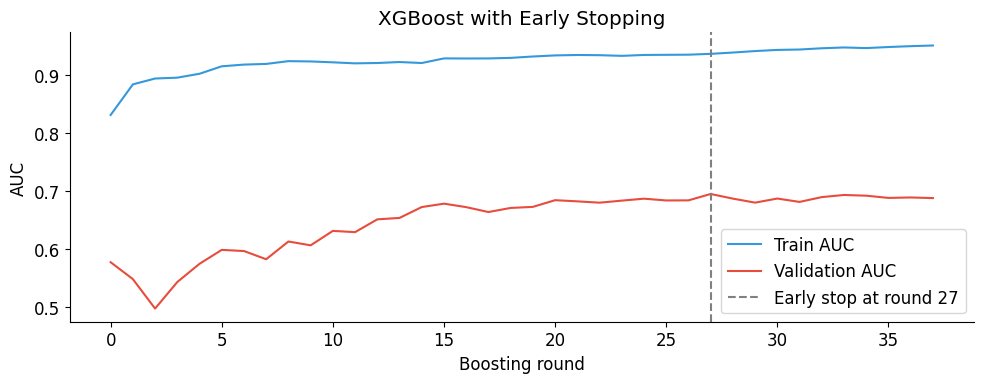

In [40]:
import xgboost as xgb

# Early stopping in XGBoost

# Split training data into train and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    Xf_train, yf_train, test_size=0.2, random_state=42, stratify=yf_train
)

# Convert data to DMatrix format for xgb.train
dtrain = xgb.DMatrix(X_tr, label=y_tr)
dval = xgb.DMatrix(X_val, label=y_val)
dtest = xgb.DMatrix(X_test)

# Define parameters for the booster
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'eta': 0.05,  # learning_rate
    'max_depth': 4,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'seed': 42,
    'nthread': -1
}

# Define the early stopping callback
early_stopping_callback = xgb.callback.EarlyStopping(
    rounds=10,
    min_delta=0,
    maximize=True, # For AUC, we want to maximize it
    data_name='validation_1',
    metric_name='auc'
)

# Train the model using xgb.train
evals_result = {}
bst = xgb.train(
    params,
    dtrain,
    num_boost_round=1000, # train up to 1000 rounds
    evals=[(dtrain, 'validation_0'), (dval, 'validation_1')],
    callbacks=[early_stopping_callback],
    verbose_eval=False, # Suppress verbose output during training
    evals_result=evals_result
)

# Extract best iteration and score from the booster
best_iteration = bst.best_iteration
best_score = bst.best_score

# Make predictions on the test set
test_pred_proba = bst.predict(dtest, iteration_range=(0, best_iteration))

print(f'Best iteration (early stopping): {best_iteration}')
print(f'Best validation AUC            : {best_score:.4f}')
print(f'Test AUC at best iteration     : {roc_auc_score(y_test, test_pred_proba):.4f}')

# Plot the training curve with the stopping point marked
train_auc_es = evals_result['validation_0']['auc']
val_auc_es   = evals_result['validation_1']['auc']

plt.figure(figsize=(10, 4))
plt.plot(train_auc_es, color='#3498db', label='Train AUC')
plt.plot(val_auc_es,   color='#e74c3c', label='Validation AUC')
plt.axvline(best_iteration, linestyle='--', color='gray',
            label=f'Early stop at round {best_iteration}')
plt.xlabel('Boosting round')
plt.ylabel('AUC')
plt.title('XGBoost with Early Stopping')
plt.legend()
plt.tight_layout()
plt.show()

### LightGBM with Early Stopping

Now, let's apply a similar early stopping approach to LightGBM. LightGBM's scikit-learn API allows for early stopping by passing `callbacks` and `eval_set` to the `fit` method.

LightGBM best iteration (early stopping): 4
LightGBM best validation AUC            : 0.6549
LightGBM Test AUC at best iteration     : 0.7676


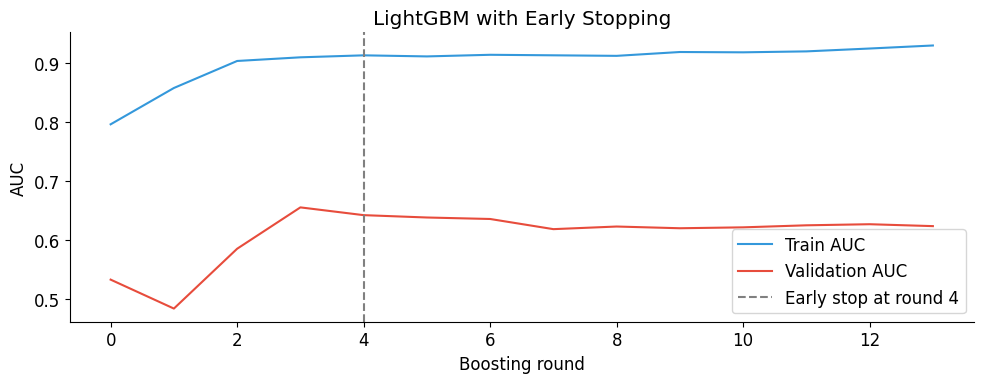

In [41]:
import lightgbm as lgb

# Define parameters for LightGBM
# Using parameters comparable to the XGBoost example
lgb_params = {
    'objective': 'binary', # For binary classification
    'metric': 'auc',
    'learning_rate': 0.05,
    'max_depth': 4,
    'num_leaves': 15, # Max_depth 4 means 2^4 - 1 = 15 leaves
    'subsample': 0.8,
    'colsample_bytree': 0.8, # Feature fraction
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1 # Suppress verbose output
}

# Initialize and train the LightGBM model
lgb_model = lgb.LGBMClassifier(**lgb_params)

lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False)],
    # `callbacks` replaces `early_stopping_rounds` for LGBMClassifier
)

# Extract best iteration and score
best_iteration_lgb = lgb_model.best_iteration_
best_score_lgb = lgb_model.best_score_['valid_1']['auc'] # Access validation AUC

# Make predictions on the test set
test_pred_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]

print(f'LightGBM best iteration (early stopping): {best_iteration_lgb}')
print(f'LightGBM best validation AUC            : {best_score_lgb:.4f}')
print(f'LightGBM Test AUC at best iteration     : {roc_auc_score(y_test, test_pred_proba_lgb):.4f}')

# Plot the training curve
train_auc_lgb = lgb_model.evals_result_['training']['auc']
val_auc_lgb = lgb_model.evals_result_['valid_1']['auc']

plt.figure(figsize=(10, 4))
plt.plot(train_auc_lgb, color='#3498db', label='Train AUC')
plt.plot(val_auc_lgb,   color='#e74c3c', label='Validation AUC')
plt.axvline(best_iteration_lgb, linestyle='--', color='gray',
            label=f'Early stop at round {best_iteration_lgb}')
plt.xlabel('Boosting round')
plt.ylabel('AUC')
plt.title('LightGBM with Early Stopping')
plt.legend()
plt.tight_layout()
plt.show()

### CatBoost with Early Stopping

Finally, let's implement early stopping for CatBoost. CatBoost's `CatBoostClassifier` also supports early stopping directly within its `fit` method using `early_stopping_rounds`.

CatBoost best iteration (early stopping): 4
CatBoost best validation AUC            : 0.7194
CatBoost Test AUC at best iteration     : 0.7677


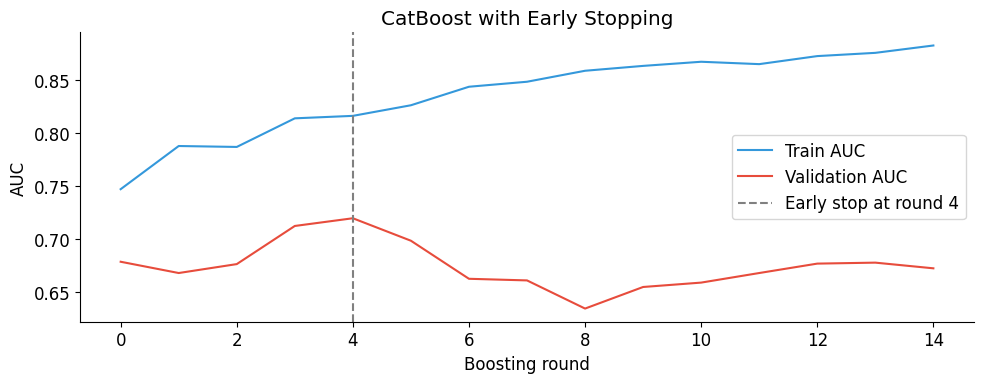

In [42]:
import catboost as cb

# Define parameters for CatBoost
# Using parameters comparable to the XGBoost example
cb_params = {
    'objective': 'Logloss', # For binary classification
    'eval_metric': 'AUC',
    'learning_rate': 0.05,
    'depth': 4,
    'subsample': 0.8,
    'colsample_bylevel': 0.8, # Feature fraction for CatBoost
    'random_seed': 42,
    'verbose': 0, # Suppress verbose output
    'thread_count': -1,
    'iterations': 1000 # Max iterations, will be stopped by early stopping
}

# Initialize and train the CatBoost model
cb_model = cb.CatBoostClassifier(**cb_params)

cb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)], # Changed here: added (X_tr, y_tr) to eval_set
    early_stopping_rounds=10,
)

# Extract best iteration and score
best_iteration_cb = cb_model.best_iteration_

# Plot the training curve to get evals_result_cb and then use it for best_score_cb
evals_result_cb = cb_model.get_evals_result()
best_score_cb = evals_result_cb['validation_1']['AUC'][best_iteration_cb] # Corrected: Access AUC from evals_result_cb at best_iteration (validation_1)

# Make predictions on the test set
test_pred_proba_cb = cb_model.predict_proba(X_test)[:, 1]

print(f'CatBoost best iteration (early stopping): {best_iteration_cb}')
print(f'CatBoost best validation AUC            : {best_score_cb:.4f}')
print(f'CatBoost Test AUC at best iteration     : {roc_auc_score(y_test, test_pred_proba_cb):.4f}')

# Plot the training curve
train_auc_cb = evals_result_cb['validation_0']['AUC'] # Corrected: Access AUC from evals_result_cb (validation_0) for training set
val_auc_cb = evals_result_cb['validation_1']['AUC'] # Corrected: Access AUC from evals_result_cb (validation_1)

plt.figure(figsize=(10, 4))
plt.plot(train_auc_cb, color='#3498db', label='Train AUC')
plt.plot(val_auc_cb,   color='#e74c3c', label='Validation AUC')
plt.axvline(best_iteration_cb, linestyle='--', color='gray',
            label=f'Early stop at round {best_iteration_cb}')
plt.xlabel('Boosting round')
plt.ylabel('AUC')
plt.title('CatBoost with Early Stopping')
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
df_fraud.head()

,transaction_amount,hour_of_day,distance_from_home,num_prev_txn_24h,is_foreign,is_online,card_age_months,account_balance,is_fraud
0,223.12,20,32.1,1,0,0,82,3619.0,0
1,133.92,4,83.2,5,0,0,5,6748.0,0
2,349.16,1,3.7,2,0,1,20,0.0,0
3,6.39,20,25.2,4,0,0,32,6364.0,0
4,330.10,23,45.0,1,1,1,17,6490.0,0


In [44]:
df_fraud.describe()

,transaction_amount,hour_of_day,distance_from_home,num_prev_txn_24h,is_foreign,is_online,card_age_months,account_balance,is_fraud
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,206.590450,11.587667,29.928700,3.020000,0.160333,0.395000,60.750667,5107.639667,0.030000
std,209.333972,6.931546,30.120795,1.800559,0.366976,0.488932,34.369350,2947.679209,0.170616
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,60.607500,6.000000,8.900000,2.000000,0.000000,0.000000,32.000000,2860.750000,0.000000
50%,146.220000,12.000000,20.900000,3.000000,0.000000,0.000000,61.000000,5085.500000,0.000000
75%,280.440000,18.000000,40.525000,4.000000,0.000000,1.000000,90.000000,7140.250000,0.000000
max,2319.740000,23.000000,251.200000,12.000000,1.000000,1.000000,119.000000,16109.000000,1.000000


In [45]:
df_fraud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_amount  3000 non-null   float64
 1   hour_of_day         3000 non-null   int64  
 2   distance_from_home  3000 non-null   float64
 3   num_prev_txn_24h    3000 non-null   int64  
 4   is_foreign          3000 non-null   int64  
 5   is_online           3000 non-null   int64  
 6   card_age_months     3000 non-null   int64  
 7   account_balance     3000 non-null   float64
 8   is_fraud            3000 non-null   int64  
dtypes: float64(3), int64(6)
memory usage: 211.1 KB


In [46]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train
)
dtrain_1 = xgb.DMatrix(X_tr, label=y_tr)
dval_1 = xgb.DMatrix(X_val, label=y_val)
dtest_1 = xgb.DMatrix(X_test)

Voting   -- AUC: 0.8428

5-fold CV AUC:
  XGBoost     : 0.7449 +/- 0.0762
  LightGBM    : 0.7037 +/- 0.1156
  CatBoost    : 0.7592 +/- 0.0884
  Voting      : 0.7509 +/- 0.0813


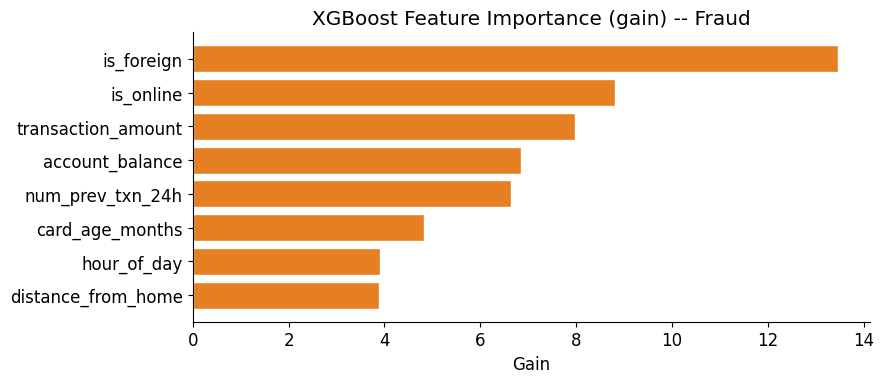


Business interpretation:
Across all three frameworks, is_foreign and is_online are the
dominant predictors of fraud, consistent with the data generation process
and known fraud patterns. The transaction_amount feature ranks third,
suggesting that Larger the transaction amount, higher the risk 
of the fraud. The ensemble (soft voting) achieves marginal gains
over individual models by averaging out framework-specific errors.
For deployment, LightGBM is recommended due to its speed advantage
at scale, with the voting ensemble reserved for maximum accuracy
settings where inference latency is acceptable.

Stacking CV AUC: 0.7462 +/- 0.0809


In [48]:
# Step 5: Soft voting
xgb_fv = xgb.XGBClassifier(n_estimators=bst.best_iteration, learning_rate=0.05,
                             max_depth=4, use_label_encoder=False,
                             eval_metric='logloss', random_state=42, n_jobs=-1)
lgb_fv = lgb.LGBMClassifier(n_estimators=lgb_model.best_iteration_, learning_rate=0.05,
                             num_leaves=31, random_state=42, n_jobs=-1, verbose=-1)
cb_fv  = cb.CatBoostClassifier(iterations=cb_model.best_iteration_, learning_rate=0.05,
                                depth=4, random_seed=42, verbose=False)
voter_f = VotingClassifier(
    estimators=[('xgb', xgb_fv), ('lgb', lgb_fv), ('cb', cb_fv)],
    voting='soft', n_jobs=-1
)
voter_f.fit(Xf_tr, yf_tr)
print(f'Voting   -- AUC: {roc_auc_score(yf_te, voter_f.predict_proba(Xf_te)[:,1]):.4f}')

# Step 6: 5-fold CV
cv_f = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print()
print('5-fold CV AUC:')
for name, clf in [('XGBoost', xgb_fv), ('LightGBM', lgb_fv),
                   ('CatBoost', cb_fv), ('Voting', voter_f)]:
    s = cross_val_score(clf, Xf, yf, cv=cv_f, scoring='roc_auc', n_jobs=-1)
    print(f'  {name:<12}: {s.mean():.4f} +/- {s.std():.4f}')

# Step 7: XGBoost feature importance
xgb_fv.fit(Xf_tr, yf_tr)
scores_f = xgb_fv.get_booster().get_score(importance_type='gain')
scores_f = dict(sorted(scores_f.items(), key=lambda x: x[1], reverse=True))
plt.figure(figsize=(9, 4))
top_f = dict(list(scores_f.items())[:8])
plt.barh(list(top_f.keys()), list(top_f.values()), color='#e67e22', edgecolor='white')
plt.gca().invert_yaxis()
plt.title('XGBoost Feature Importance (gain) -- Fraud')
plt.xlabel('Gain')
plt.tight_layout()
plt.show()

# Step 8
print('''
Business interpretation:
Across all three frameworks, is_foreign and is_online are the
dominant predictors of fraud, consistent with the data generation process
and known fraud patterns. The transaction_amount feature ranks third,
suggesting that Larger the transaction amount, higher the risk
of the fraud. The ensemble (soft voting) achieves marginal gains
over individual models by averaging out framework-specific errors.
For deployment, LightGBM is recommended due to its speed advantage
at scale, with the voting ensemble reserved for maximum accuracy
settings where inference latency is acceptable.
''')

# Stretch: Stacking
stacker_f = StackingClassifier(
    estimators=[('xgb', xgb_fv), ('lgb', lgb_fv), ('cb', cb_fv)],
    final_estimator=LogisticRegression(C=1.0, random_state=42),
    cv=5, stack_method='predict_proba', n_jobs=-1
)
s_stack = cross_val_score(stacker_f, Xf, yf, cv=cv_f, scoring='roc_auc', n_jobs=-1)
print(f'Stacking CV AUC: {s_stack.mean():.4f} +/- {s_stack.std():.4f}')
